Scanning 3656 npz files in /Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/audio_features


Aggregating annotations: 100%|████████████| 3656/3656 [00:02<00:00, 1407.03it/s]



Done in 2.6s
  Total files       : 3656
  Total segments    : 168,239
  Total seconds     : 84,120 (at hop=0.5s)
  Number of classes : 15

--- Per-class summary (ascending by segment count) ---
                class_name  n_segments  pct_of_segments  n_files  pct_of_files  imbalance_ratio_vs_max  deficit_to_median
              light_switch        1047             0.62      354          9.68                   24.53               8389
              bell_ringing        2541             1.51      276          7.55                   10.11               6895
         window_open_close        2911             1.73      472         12.91                    8.82               6525
wardrobe_drawer_open_close        4568             2.72      592         16.19                    5.62               4868
           toilet_flushing        6368             3.79      405         11.08                    4.03               3068
            coffee_machine        6898             4.10      207         

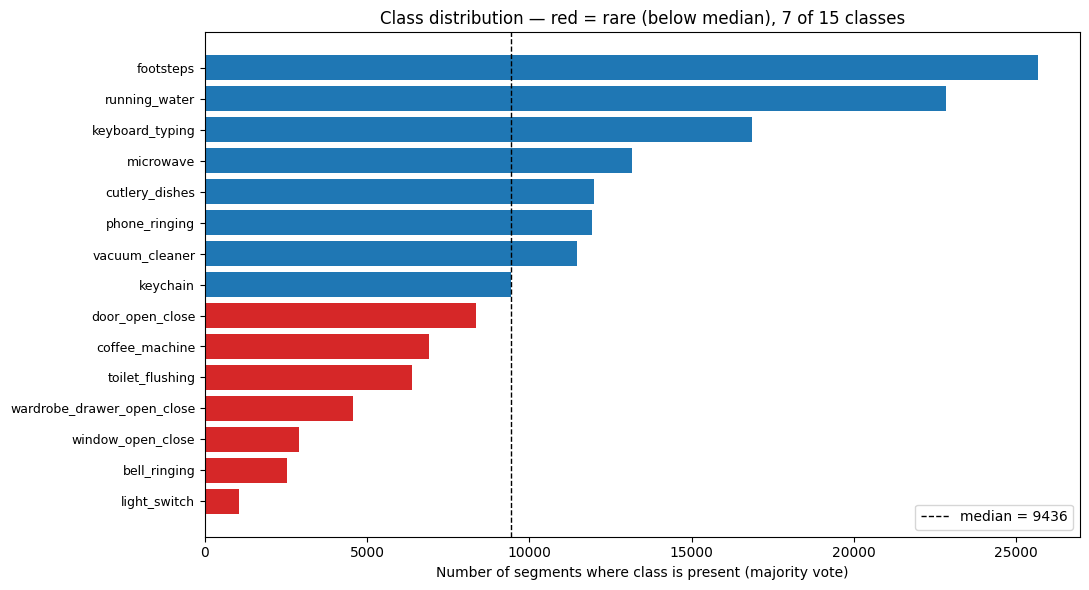

✓ Plot saved to /Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/class_distribution.png


In [1]:
# ============================================================================
# CELL 2 — Aggregate annotations and identify rare classes
# ============================================================================

import json
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm import tqdm



# --- 2.1 Load CONFIG -------------------------------------------------------
from pathlib import Path
import json

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'config.json').is_file() and (p / 'data').is_dir():
            return p
    raise RuntimeError("project root (config.json + data/) not found above cwd")

ROOT = find_root()
with open(ROOT / 'config.json') as f:
    CONFIG = json.load(f)
P = CONFIG['paths']

ORIG_AUDIO_DIR = ROOT / P['orig_audio']
ORIG_NPZ_DIR   = ROOT / P['orig_npz']
AUG_AUDIO_DIR  = ROOT / P['aug_audio']
AUG_NPZ_DIR    = ROOT / P['aug_npz']

# --- 2.2 Aggregation hyperparameters --------------------------------------
ANNOTATOR_AGREEMENT_THRESHOLD = 0.5   # majority vote
SEGMENT_OVERLAP_THRESHOLD     = 0.5   # how much of the 1s window must contain
                                       # the class for it to count
SEGMENT_DURATION_S            = CONFIG["segment_window_s"]   # 1.0
SEGMENT_HOP_S                 = CONFIG["segment_hop_s"]      # 0.5

# --- 2.3 Walk all npz files, aggregate, accumulate counts -----------------
npz_files = sorted(ORIG_NPZ_DIR.glob("*.npz"))
print(f"Scanning {len(npz_files)} npz files in {ORIG_NPZ_DIR}")

class_names = None              # set from first file, then validated against rest
total_segments_global = 0       # total 1-second segments across the whole corpus
class_segment_counts = None     # ndarray [C], counts per class

# Per-file detail — used by Cell 3 (donor selection).
per_file_records = []           # list of dicts, one per file

t0 = time.time()
for npz_path in tqdm(npz_files, desc="Aggregating annotations"):
    with np.load(npz_path, allow_pickle=True) as f:
        ann       = f["annotations"]                  # [T, C, A]
        cls_names = list(f["class_names"])

    # Validate class-name alignment across files.
    if class_names is None:
        class_names = cls_names
        C = len(class_names)
        class_segment_counts = np.zeros(C, dtype=np.int64)
    elif cls_names != class_names:
        raise ValueError(f"class_names mismatch in {npz_path.name}")

    T_seg, C, A = ann.shape

    # Step 1: per-segment, per-class — fraction of annotators who marked it.
    # ann[t, c, a] in [0, 1] indicates overlap fraction. Binarize per annotator
    # via SEGMENT_OVERLAP_THRESHOLD, then take fraction across annotators.
    annot_binary    = (ann >= SEGMENT_OVERLAP_THRESHOLD).astype(np.float32)  # [T,C,A]
    annot_agreement = annot_binary.mean(axis=2)                              # [T,C]
    label           = (annot_agreement >= ANNOTATOR_AGREEMENT_THRESHOLD)     # [T,C]

    # Step 2: accumulate global counts.
    file_counts = label.sum(axis=0)                   # [C], segments per class
    class_segment_counts += file_counts.astype(np.int64)
    total_segments_global += T_seg

    # Step 3: keep per-file record for Cell 3 (donor selection).
    per_file_records.append({
        "filename":              npz_path.stem,
        "n_segments":            T_seg,
        "class_segment_counts":  file_counts,         # [C]
        "label":                 label,               # [T, C] — bool
        "agreement":             annot_agreement,     # [T, C] — for purity scoring
    })

print(f"\nDone in {time.time()-t0:.1f}s")
print(f"  Total files       : {len(npz_files)}")
print(f"  Total segments    : {total_segments_global:,}")
print(f"  Total seconds     : {total_segments_global * SEGMENT_HOP_S:,.0f} "
      f"(at hop={SEGMENT_HOP_S}s)")
print(f"  Number of classes : {C}")

# --- 2.4 Build a per-class summary table ----------------------------------
# We report several views: raw segment count, percentage, presence in files,
# and the "median-target" budget (for Cell 5).
files_with_class = np.zeros(C, dtype=np.int64)
for rec in per_file_records:
    files_with_class += (rec["class_segment_counts"] > 0).astype(np.int64)

summary = pd.DataFrame({
    "class_name":      class_names,
    "n_segments":      class_segment_counts,
    "pct_of_segments": class_segment_counts / total_segments_global * 100,
    "n_files":         files_with_class,
    "pct_of_files":    files_with_class / len(npz_files) * 100,
}).sort_values("n_segments", ascending=True).reset_index(drop=True)

# Imbalance metrics relative to the corpus.
median_count = int(summary["n_segments"].median())
max_count    = int(summary["n_segments"].max())
summary["imbalance_ratio_vs_max"]    = max_count / summary["n_segments"].clip(lower=1)
summary["deficit_to_median"]         = (median_count - summary["n_segments"]).clip(lower=0)
summary["deficit_to_median"]         = summary["deficit_to_median"].astype(int)

print("\n--- Per-class summary (ascending by segment count) ---")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# --- 2.5 Highlight the imbalance -----------------------------------------
print("\n--- Imbalance summary ---")
print(f"  Most common class    : {summary.iloc[-1]['class_name']:30s} "
      f"({int(summary.iloc[-1]['n_segments']):,} segs)")
print(f"  Median class         : {int(median_count):,} segs")
print(f"  Least common class   : {summary.iloc[0]['class_name']:30s} "
      f"({int(summary.iloc[0]['n_segments']):,} segs)")
print(f"  Max:Min ratio        : "
      f"{summary['imbalance_ratio_vs_max'].iloc[0]:.1f}x")

# Choose rare classes: those below the median. These are augmentation targets.
RARE_CLASS_RULE = "below_median"   # alternatives: "below_quartile", "fixed_floor"
if RARE_CLASS_RULE == "below_median":
    rare_mask = summary["n_segments"] < median_count
elif RARE_CLASS_RULE == "below_quartile":
    q1 = summary["n_segments"].quantile(0.25)
    rare_mask = summary["n_segments"] < q1
elif RARE_CLASS_RULE == "fixed_floor":
    FLOOR = max_count // 4
    rare_mask = summary["n_segments"] < FLOOR
else:
    raise ValueError(RARE_CLASS_RULE)

rare_classes = summary.loc[rare_mask, "class_name"].tolist()
print(f"\n--- Rare classes ({RARE_CLASS_RULE}, {len(rare_classes)} of {C}) ---")
for _, row in summary[rare_mask].iterrows():
    print(f"  {row['class_name']:30s}  "
          f"current={int(row['n_segments']):>5d}   "
          f"target={median_count:>5d}   "
          f"deficit={int(row['deficit_to_median']):>5d}")

# --- 2.6 Persist for downstream cells -------------------------------------
summary.to_csv(ROOT / P['aug_artifacts'] / "class_distribution.csv", index=False)
print(f"\n✓ Class distribution saved to {ROOT / P['aug_artifacts'] / 'class_distribution.csv'}")

# Save the heavy per-file structures for Cell 3 (don't reload npz in Cell 3).
np.savez_compressed(
    ROOT / P['aug_artifacts'] / "annotations_aggregated.npz",
    class_names         = np.array(class_names),
    class_segment_counts= class_segment_counts,
    median_count        = np.int64(median_count),
    rare_class_mask     = rare_mask.values,
    filenames           = np.array([r["filename"] for r in per_file_records]),
    n_segments_per_file = np.array([r["n_segments"] for r in per_file_records]),
    # Stack labels and agreement per file. They're variable-length in T_seg, so
    # we store them as object arrays — np.savez handles this natively.
    labels_per_file     = np.array([r["label"]     for r in per_file_records],
                                    dtype=object),
    agreement_per_file  = np.array([r["agreement"] for r in per_file_records],
                                    dtype=object),
)
print(f"✓ Aggregated annotations saved to {ROOT / P['aug_artifacts'] / 'annotations_aggregated.npz'}")

# --- 2.7 Quick visualization ----------------------------------------------
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 6))
y_pos = np.arange(C)
colors = ["tab:red" if rare_mask.iloc[i] else "tab:blue" for i in range(C)]
ax.barh(y_pos, summary["n_segments"], color=colors)
ax.set_yticks(y_pos)
ax.set_yticklabels(summary["class_name"], fontsize=9)
ax.axvline(median_count, color="black", linestyle="--", linewidth=1,
           label=f"median = {median_count}")
ax.set_xlabel("Number of segments where class is present (majority vote)")
ax.set_title(f"Class distribution — red = rare (below median), "
             f"{len(rare_classes)} of {C} classes")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(ROOT / P['aug_artifacts'] / "class_distribution.png", dpi=120)
plt.show()
print(f"✓ Plot saved to {ROOT / P['aug_artifacts'] / 'class_distribution.png'}")

In [3]:
# ============================================================================
# CELL 2.5 — Patch: recompute rare_class_mask in correct class ordering
# ============================================================================

# Re-load whatever Cell 2 saved (everything is correct EXCEPT rare_class_mask).
agg = dict(np.load(ROOT / P['aug_artifacts'] / "annotations_aggregated.npz", allow_pickle=True))

class_names          = list(agg["class_names"])
class_segment_counts = agg["class_segment_counts"]
median_count         = int(agg["median_count"])

# Recompute the rare-class mask aligned with class_names (alphabetical order
# matching the annotation array's class dimension).
rare_class_mask_correct = class_segment_counts < median_count

agg["rare_class_mask"] = rare_class_mask_correct
np.savez_compressed(ROOT / P['aug_artifacts'] / "annotations_aggregated.npz", **agg)

# Verify the fix.
print("Corrected rare classes (in class_names ordering):")
print(f"{'idx':>3s}  {'class':30s}  {'count':>7s}  {'rare?':>6s}")
print("-" * 55)
for idx, (c, count, is_rare) in enumerate(
    zip(class_names, class_segment_counts, rare_class_mask_correct)
):
    flag = "★" if is_rare else " "
    print(f"{idx:>3d}  {c:30s}  {int(count):>7,d}  {flag:>6s}")

n_rare = int(rare_class_mask_correct.sum())
print(f"\n✓ {n_rare} rare classes (below median = {median_count})")
print("✓ Mask re-saved to annotations_aggregated.npz")

Corrected rare classes (in class_names ordering):
idx  class                             count   rare?
-------------------------------------------------------
  0  bell_ringing                      2,541       ★
  1  coffee_machine                    6,898       ★
  2  cutlery_dishes                   11,976        
  3  door_open_close                   8,347       ★
  4  footsteps                        25,685        
  5  keyboard_typing                  16,868        
  6  keychain                          9,436        
  7  light_switch                      1,047       ★
  8  microwave                        13,167        
  9  phone_ringing                    11,927        
 10  running_water                    22,835        
 11  toilet_flushing                   6,368       ★
 12  vacuum_cleaner                   11,452        
 13  wardrobe_drawer_open_close        4,568       ★
 14  window_open_close                 2,911       ★

✓ 7 rare classes (below median = 9436)
✓ Mask

In [4]:
# ============================================================================
# CELL 3 — Identify high-quality donor clips per rare class
# ============================================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

# --- 3.1 Load aggregated annotations from Cell 2 ---------------------------
agg = np.load(ROOT / P['aug_artifacts'] / "annotations_aggregated.npz", allow_pickle=True)
class_names         = list(agg["class_names"])
class_segment_counts= agg["class_segment_counts"]
median_count        = int(agg["median_count"])
rare_class_mask     = agg["rare_class_mask"]
filenames           = list(agg["filenames"])
n_segments_per_file = agg["n_segments_per_file"]
labels_per_file     = agg["labels_per_file"]      # list of [T, C] bool
agreement_per_file  = agg["agreement_per_file"]   # list of [T, C] float in [0,1]

C = len(class_names)
F = len(filenames)
rare_classes = [c for c, is_rare in zip(class_names, rare_class_mask) if is_rare]
rare_class_idx = [class_names.index(c) for c in rare_classes]
print(f"Donor search across {F} files for {len(rare_classes)} rare classes:")
for c in rare_classes:
    print(f"  {c}")

# --- 3.2 Donor-segment scoring --------------------------------------------
# For each rare class c and each segment t in each file f, compute:
#   score(f, t, c) = present(f,t,c) * agreement(f,t,c) * purity(f,t,c)
# where:
#   present   = 1 if class is present (binary label)
#   agreement = annotator-agreement score in [0, 1]; we want strong agreement
#   purity    = 1 / (1 + n_other_classes_present)  — rewards clips with rare
#               class alone or with few co-occurrences
# Higher score = better donor.

PURITY_DECAY  = 1.0   # 1.0 = strong purity preference. 0.5 = mild.
MIN_AGREEMENT = 0.5   # ignore segments where the rare class barely scrapes by

donor_records = []   # list of dicts: filename, class, t_seg, score, n_co_occur

for f_idx, fname in enumerate(filenames):
    label_f     = labels_per_file[f_idx].astype(bool)        # [T, C]
    agreement_f = agreement_per_file[f_idx].astype(np.float32)  # [T, C]
    T_seg = label_f.shape[0]

    # n_classes_present per segment
    n_present_per_seg = label_f.sum(axis=1)                  # [T]
    purity = 1.0 / (1.0 + PURITY_DECAY * (n_present_per_seg - 1).clip(min=0))  # [T]

    for c in rare_classes:
        c_idx = class_names.index(c)

        present = label_f[:, c_idx]                          # [T] bool
        agree   = agreement_f[:, c_idx]                      # [T]

        # Filter: must be present and have decent agreement.
        candidate_mask = present & (agree >= MIN_AGREEMENT)
        if not candidate_mask.any():
            continue

        # Compute scores ONLY for candidates (saves memory).
        cand_t = np.where(candidate_mask)[0]
        for t in cand_t:
            donor_records.append({
                "filename":    fname,
                "class":       c,
                "t_seg":       int(t),
                "agreement":   float(agree[t]),
                "n_co_occur":  int(n_present_per_seg[t] - 1),
                "purity":      float(purity[t]),
                "score":       float(agree[t] * purity[t]),
            })

donors_df = pd.DataFrame(donor_records)
print(f"\nTotal donor segments found: {len(donors_df):,}")

# --- 3.3 Per-class donor pool summary -------------------------------------
print("\n--- Donor pool size per rare class ---")
print(f"{'class':30s}  {'segments':>10s}  {'files':>8s}  {'mean_score':>11s}  "
      f"{'pure_frac':>10s}")
print("-" * 75)
for c in rare_classes:
    sub = donors_df[donors_df["class"] == c]
    if len(sub) == 0:
        print(f"{c:30s}  {'NONE':>10s}")
        continue
    pure_frac = (sub["n_co_occur"] == 0).mean()
    print(f"{c:30s}  {len(sub):>10,d}  "
          f"{sub['filename'].nunique():>8,d}  "
          f"{sub['score'].mean():>11.4f}  "
          f"{pure_frac:>10.2%}")

# --- 3.4 Sanity check: do donor counts match Cell 2 segment counts? -------
# They should be exactly equal (donor candidates are precisely "segments where
# class is present with adequate agreement"). If they're lower, MIN_AGREEMENT
# is filtering some out — that's by design.
print("\n--- Sanity check ---")
print(f"{'class':30s}  {'donors':>8s}  {'cell_2':>8s}  {'kept_pct':>9s}")
print("-" * 60)
for c, c_idx in zip(rare_classes, rare_class_idx):
    donor_count = (donors_df["class"] == c).sum()
    cell2_count = int(class_segment_counts[c_idx])
    kept_pct = donor_count / cell2_count * 100 if cell2_count else 0.0
    print(f"{c:30s}  {donor_count:>8,d}  {cell2_count:>8,d}  "
          f"{kept_pct:>8.1f}%")

# --- 3.5 Convert per-segment donors → per-event donors --------------------
# Augmenting one segment at a time is wasteful — pitch-shifting a 1-second snip
# is poor material. Instead we group consecutive donor segments of the same
# class in the same file into "events" and augment whole events. Each event
# becomes one donor unit.
print("\nGrouping consecutive donor segments into events...")

def group_events(df_sub):
    """Group consecutive t_seg into contiguous runs."""
    df_sub = df_sub.sort_values("t_seg").reset_index(drop=True)
    if len(df_sub) == 0:
        return pd.DataFrame()
    # Consecutive-run detection: gaps in t_seg break events.
    breaks = (df_sub["t_seg"].diff() > 1).cumsum()
    events = df_sub.groupby(breaks).agg(
        filename     = ("filename",    "first"),
        cls          = ("class",       "first"),
        t_start      = ("t_seg",       "min"),
        t_end        = ("t_seg",       "max"),
        n_segments   = ("t_seg",       "count"),
        mean_score   = ("score",       "mean"),
        mean_purity  = ("purity",      "mean"),
        max_co_occur = ("n_co_occur",  "max"),
    ).reset_index(drop=True)
    return events

events_list = []
for (fname, c), sub in donors_df.groupby(["filename", "class"]):
    events_list.append(group_events(sub))
events_df = pd.concat(events_list, ignore_index=True) if events_list else pd.DataFrame()

# Convert segment indices to actual onset/offset times (seconds).
# segment t covers [t * hop_s, t * hop_s + window_s].
hop_s    = CONFIG["segment_hop_s"]
window_s = CONFIG["segment_window_s"]
events_df["onset_s"]    = events_df["t_start"] * hop_s
events_df["offset_s"]   = events_df["t_end"]   * hop_s + window_s
events_df["duration_s"] = events_df["offset_s"] - events_df["onset_s"]

# Final donor ranking score combines event quality and length.
# We slightly prefer longer events (more material per augmentation) but cap the
# benefit so a 30s event isn't 30x preferred over a 1s event.
events_df["donor_score"] = (
    events_df["mean_score"] * np.log1p(events_df["n_segments"])
)
events_df = events_df.sort_values(
    ["cls", "donor_score"], ascending=[True, False]
).reset_index(drop=True)

print(f"Total donor events: {len(events_df):,}")

# --- 3.6 Per-class event pool summary -------------------------------------
print("\n--- Event pool per rare class ---")
print(f"{'class':30s}  {'events':>8s}  {'tot_segs':>9s}  "
      f"{'med_dur':>8s}  {'pure%':>7s}")
print("-" * 72)
for c in rare_classes:
    sub = events_df[events_df["cls"] == c]
    if len(sub) == 0:
        print(f"{c:30s}  {'NONE':>8s}")
        continue
    pure_frac = (sub["max_co_occur"] == 0).mean()
    print(f"{c:30s}  {len(sub):>8,d}  "
          f"{int(sub['n_segments'].sum()):>9,d}  "
          f"{sub['duration_s'].median():>7.1f}s  "
          f"{pure_frac:>6.1%}")

# --- 3.7 Persist for Cell 5 -----------------------------------------------
events_df.to_csv(ROOT / P['aug_artifacts'] / "donor_events.csv", index=False)
print(f"\n✓ Donor events saved to {ROOT / P['aug_artifacts'] / 'donor_events.csv'}")
print(f"  ({len(events_df):,} rows; columns: "
      f"{', '.join(events_df.columns.tolist())})")

Donor search across 3656 files for 7 rare classes:
  bell_ringing
  coffee_machine
  door_open_close
  light_switch
  toilet_flushing
  wardrobe_drawer_open_close
  window_open_close

Total donor segments found: 32,680

--- Donor pool size per rare class ---
class                             segments     files   mean_score   pure_frac
---------------------------------------------------------------------------
bell_ringing                         2,541       276       0.6695      53.52%
coffee_machine                       6,898       207       0.7543      64.11%
door_open_close                      8,347     1,155       0.6824      66.20%
light_switch                         1,047       354       0.5973      71.44%
toilet_flushing                      6,368       405       0.7630      71.04%
wardrobe_drawer_open_close           4,568       592       0.7193      75.61%
window_open_close                    2,911       472       0.7472      78.15%

--- Sanity check ---
class              

In [5]:
pip install audiomentations

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for numpy-minmax: filename=numpy_minmax-0.5.0-cp314-cp314-macosx_12_0_arm64.whl size=12367 sha256=0d1e542fd145f4f4cb06845e0f65e40c69ab66d0a2a3a9130d81515dbc0e01d4
  Stored in directory: /Users/amrabdullah/Library/Caches/pip/wheels/a6/30/d6/01c20dd204f8f62a3037a6496eb1e6bd40604670582db49ece
  Created wheel for numpy-rms: filename=numpy_rms-0.6.0-cp314-cp314-macosx_12_0_arm64.whl size=10540 sha256=c4f9a37402ac14aff2e6b72e0625b842d06b1fd1ee5b09eeb76587e4365caec2
  Stored in directory: /Users/amrabdullah/Library/Caches/pip/wheels/74/ad/ae/7fe9e88d043a717251cf5565346a2890a84d38570dc91d25da
Successfully built numpy-minmax numpy-rms
  Attempting uninstall: soxr
    Found existing installation: soxr 1.0.0
    Uni

In [9]:
# ============================================================================
# Fix filename zero-padding in donor_events.csv
# ============================================================================
import pandas as pd
from pathlib import Path

ORIG_AUDIO_DIR = Path(CONFIG["paths"]["orig_audio"])

# Read with filename forced to string (prevents int-coercion).
donors_df = pd.read_csv(
    ROOT / P['aug_artifacts'] / "donor_events.csv",
    dtype={"filename": str}
)

# Detect the zero-padding width by looking at actual files on disk.
sample_files = [p.stem for p in ORIG_AUDIO_DIR.glob("*.wav")][:10]
pad_widths = {len(s) for s in sample_files}
assert len(pad_widths) == 1, f"Inconsistent filename lengths in audio dir: {pad_widths}"
PAD_WIDTH = pad_widths.pop()
print(f"Detected zero-pad width: {PAD_WIDTH} (e.g. {sample_files[0]}.wav)")

# Apply zero-padding to whatever pandas read in.
def normalize_filename(fn):
    """Coerce filename to canonical zero-padded form."""
    s = str(fn).strip()
    # Strip any extension if it crept in.
    if "." in s:
        s = s.rsplit(".", 1)[0]
    # Zero-pad to detected width.
    return s.zfill(PAD_WIDTH)

donors_df["filename"] = donors_df["filename"].apply(normalize_filename)

# Verify a sample of filenames now resolve to actual files.
n_check = min(20, len(donors_df))
n_found = sum(
    (ORIG_AUDIO_DIR / f"{fn}.wav").exists()
    for fn in donors_df["filename"].head(n_check)
)
print(f"Sanity: {n_found}/{n_check} of first donors resolve to actual .wav files.")
assert n_found == n_check, "Filename normalization didn't fix the lookup."

# Re-save with explicit string filenames (quoted, to prevent re-coercion).
donors_df.to_csv(ROOT / P['aug_artifacts'] / "donor_events.csv", index=False)
print(f"✓ Re-saved {len(donors_df):,} rows with normalized filenames.")
print(f"  First 5 filenames: {donors_df['filename'].head().tolist()}")

# Also fix annotations_aggregated.npz if its filenames have the same issue.
agg = dict(np.load(ROOT / P['aug_artifacts'] / "annotations_aggregated.npz", allow_pickle=True))
agg_filenames = [str(f) for f in agg["filenames"]]
if any(len(f) != PAD_WIDTH for f in agg_filenames):
    print(f"\nFixing filenames in annotations_aggregated.npz too...")
    agg["filenames"] = np.array([normalize_filename(f) for f in agg_filenames])
    np.savez_compressed(ROOT / P['aug_artifacts'] / "annotations_aggregated.npz", **agg)
    print(f"✓ Re-saved annotations_aggregated.npz")
else:
    print(f"\n✓ Filenames in annotations_aggregated.npz already correct.")

Detected zero-pad width: 6 (e.g. 001167.wav)
Sanity: 20/20 of first donors resolve to actual .wav files.
✓ Re-saved 5,374 rows with normalized filenames.
  First 5 filenames: ['003583', '004739', '001904', '005577', '001947']

✓ Filenames in annotations_aggregated.npz already correct.


In [12]:
# ============================================================================
# CELL 4 — Augmentation menu definition
# ============================================================================

# --- 4.1 Install audiomentations if not present ---------------------------
# Run once: pip install audiomentations
# (No torch dependency. Pure CPU. Returns numpy arrays.)
import audiomentations as AA
import numpy as np
import json
from pathlib import Path

# --- 4.2 Load CONFIG and rare-class metadata ------------------------------
with open(ROOT / "config.json") as f:
    CONFIG = json.load(f)

agg = np.load(ROOT / P['aug_artifacts'] / "annotations_aggregated.npz", allow_pickle=True)
class_names         = list(agg["class_names"])
rare_class_mask     = agg["rare_class_mask"]
rare_classes = [c for c, r in zip(class_names, rare_class_mask) if r]

SAMPLE_RATE = CONFIG["sample_rate"]   # 48000

# --- 4.3 Per-augmentation factories ---------------------------------------
# Each factory returns a fresh `audiomentations.Compose` instance with
# RANDOMIZED parameters within configured bounds. Calling the factory each
# time we generate a clip ensures that each augmented sample gets its own
# random draw — that's where diversity comes from.

def aug_pitch_shift(p=1.0, min_semitones=-2.0, max_semitones=2.0):
    """Shift pitch up/down. Preserves duration. Label-preserving.
    Why: changes spectral position but keeps temporal structure intact.
    Why bounded to ±2: beyond this, sounds become recognizably 'modified'
    (e.g. a pitch-shifted bell starts sounding like a different bell)."""
    return AA.PitchShift(
        min_semitones=min_semitones, max_semitones=max_semitones, p=p
    )

def aug_gain(p=1.0, min_gain_db=-6.0, max_gain_db=6.0):
    """Scale loudness up/down. Preserves duration. Label-preserving.
    Why: simulates microphone-distance variation and recording-level diff.
    Why bounded to ±6 dB: ~factor of 2 amplitude. Beyond this, you risk
    clipping (loud) or pushing signals into the noise floor (quiet)."""
    return AA.Gain(min_gain_db=min_gain_db, max_gain_db=max_gain_db, p=p)

def aug_gaussian_noise(p=1.0, min_snr_db=15.0, max_snr_db=30.0):
    """Add Gaussian noise at controlled SNR. Preserves duration. Label-pres.
    Why: simulates microphone self-noise, distant ambient hiss.
    Why bounded to SNR ≥ 15 dB: lower SNR starts masking the actual class
    signal (especially for quiet events like light_switch)."""
    return AA.AddGaussianSNR(
        min_snr_db=min_snr_db, max_snr_db=max_snr_db, p=p
    )

def aug_polarity_inversion(p=1.0):
    """Flip waveform sign. Preserves everything spectral; perceptually
    inaudible. Label-preserving.
    Why include it at all: it changes the raw waveform exactly while leaving
    mel-spectrograms unchanged. It's a 'free' augmentation for waveform-input
    classifiers but a no-op for spectrogram-input classifiers. Including it
    costs nothing and preserves labels perfectly."""
    return AA.PolarityInversion(p=p)

def aug_time_stretch(p=1.0, min_rate=0.9, max_rate=1.1):
    """Stretch audio in time without changing pitch. CHANGES DURATION.
    NOT strictly label-preserving — onsets/offsets get rescaled.
    Why bounded to 0.9–1.1: stronger stretches introduce audible artifacts
    (warbling, smearing of transients) and compound with the pitch-shift
    artifacts in audiomentations' librosa-backend implementation."""
    return AA.TimeStretch(
        min_rate=min_rate, max_rate=max_rate, p=p, leave_length_unchanged=False
    )

def aug_shift(p=1.0, min_shift=-0.2, max_shift=0.2):
    """Roll the waveform circularly by a fraction of its length.
    For event-cropped donors this is benign — the event stays in the clip
    but its position within the clip changes. Preserves labels in the sense
    that the same class is present, but onsets/offsets shift.
    Why bounded to ±20%: larger shifts can push the event partly off the
    edge for short clips."""
    return AA.Shift(min_shift=min_shift, max_shift=max_shift,
                    rollover=True, p=p)

# --- 4.4 Build the per-class menu -----------------------------------------
# Each entry specifies:
#   - 'always': transforms applied to every sample (full Compose).
#   - 'choose_n_from': pool of optional transforms; we pick N at random per
#                      sample (more diversity than always-on).
#   - 'time_stretch': bool — whether to allow time-stretch (off for short
#                      impulsive classes; this means Cell 7 doesn't need to
#                      rescale labels for that class's augmented clips).
#   - 'min_event_duration_for_stretch': don't stretch events shorter than X
#                      even within classes that allow stretch.

# Every class gets these label-preserving, duration-preserving augmentations
# as its base. Per-clip we pick 2 of them at random from the optional pool.
BASE_OPTIONAL_POOL = [
    aug_pitch_shift,
    aug_gain,
    aug_gaussian_noise,
    aug_polarity_inversion,
    aug_shift,
]

AUG_MENU = {
    # --- Impulsive / short events: NO time-stretch -------------------------
    "light_switch": {
        "time_stretch":                  False,
        "min_event_duration_for_stretch": float("inf"),
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Click-like; transients critical.",
    },
    "door_open_close": {
        "time_stretch":                  False,
        "min_event_duration_for_stretch": float("inf"),
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Impulsive; preserve transients.",
    },
    "wardrobe_drawer_open_close": {
        "time_stretch":                  False,
        "min_event_duration_for_stretch": float("inf"),
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Impulsive; preserve transients.",
    },
    "window_open_close": {
        "time_stretch":                  False,
        "min_event_duration_for_stretch": float("inf"),
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Impulsive; preserve transients.",
    },

    # --- Sustained events: time-stretch allowed for events ≥ 3s -----------
    "bell_ringing": {
        "time_stretch":                  True,
        "min_event_duration_for_stretch": 3.0,
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Sustained tones; time-stretch safe.",
    },
    "toilet_flushing": {
        "time_stretch":                  True,
        "min_event_duration_for_stretch": 3.0,
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Sustained noise; full menu safe.",
    },
    "coffee_machine": {
        "time_stretch":                  True,
        "min_event_duration_for_stretch": 3.0,
        "optional_pool":                  BASE_OPTIONAL_POOL,
        "n_optional_per_sample":          2,
        "notes":                          "Long sustained; ideal for full menu.",
    },
}

# Sanity: every rare class has a menu entry.
missing = set(rare_classes) - set(AUG_MENU.keys())
assert not missing, f"Missing menu entries for: {missing}"
extra = set(AUG_MENU.keys()) - set(rare_classes)
assert not extra,   f"Menu has entries for non-rare classes: {extra}"
print(f"✓ AUG_MENU defined for all {len(rare_classes)} rare classes.")

# --- 4.5 Compose-builder for one augmentation sample ----------------------
def build_augmentation_pipeline(class_name, event_duration_s, rng):
    """Construct a randomized augmentation Compose for one sample.
    
    Args:
      class_name: which rare class this donor event belongs to.
      event_duration_s: duration of the donor event in seconds (used to
                        decide whether to enable time-stretch).
      rng: numpy Generator for reproducible random sampling of which
           optional augmentations to include this time.
    
    Returns:
      (compose, applied_transforms) where:
        compose: an audiomentations.Compose that will be called on a
                 numpy waveform.
        applied_transforms: a list of transform-name strings (for the
                            provenance manifest in Cell 6).
    """
    menu = AUG_MENU[class_name]
    transforms = []
    applied_names = []

    # 1) Optionally include time-stretch (only for sustained classes with
    #    long enough events). Lower probability than other augmentations so
    #    we don't overwhelm the pool with stretched samples.
    if (menu["time_stretch"] and
        event_duration_s >= menu["min_event_duration_for_stretch"] and
        rng.random() < 0.5):
        transforms.append(aug_time_stretch(p=1.0))
        applied_names.append("TimeStretch")

    # 2) Pick N transforms at random from the optional pool. Each chosen
    #    transform has p=1.0 so it always fires; randomness comes from
    #    WHICH transforms get chosen and what parameters get drawn inside.
    pool = menu["optional_pool"]
    n_pick = menu["n_optional_per_sample"]
    chosen_idx = rng.choice(len(pool), size=min(n_pick, len(pool)),
                            replace=False)
    for i in chosen_idx:
        t = pool[i](p=1.0)
        transforms.append(t)
        applied_names.append(type(t).__name__)

    return AA.Compose(transforms), applied_names

# --- 4.6 Smoke test on one donor event ------------------------------------
# Apply the augmentation to a real donor event end-to-end so we catch any
# import or shape error before Cell 6 runs the full generation loop.
import pandas as pd
import soundfile as sf

# Detect zero-pad width from the audio directory (same logic as Cell 4.5,
# defined locally so this cell is self-contained).
ORIG_AUDIO_DIR = Path(CONFIG["paths"]["orig_audio"])
_sample_stems = [p.stem for p in ORIG_AUDIO_DIR.glob("*.wav")][:10]
PAD_WIDTH = len(_sample_stems[0]) if _sample_stems else 6

def normalize_filename(fn):
    """Single source of truth for filename canonicalization. Used by every
    cell that resolves a filename to a path. Robust against pandas int
    coercion, accidental extension inclusion, and width inconsistencies."""
    s = str(fn).strip()
    if "." in s:
        s = s.rsplit(".", 1)[0]
    return s.zfill(PAD_WIDTH)

# Critical: read CSV with filename forced to string. Otherwise pandas
# coerces "003583" → 3583 on import.
donors_df = pd.read_csv(
    ROOT / P['aug_artifacts'] / "donor_events.csv",
    dtype={"filename": str}
)
# Belt-and-suspenders: also pass through normalize_filename in case the
# saved file has any inconsistency. Cheap, idempotent.
donors_df["filename"] = donors_df["filename"].apply(normalize_filename)

print("\n--- Smoke test (1 augmentation per rare class) ---")
rng = np.random.default_rng(seed=42)

for c in rare_classes:
    sub = donors_df[donors_df["cls"] == c]
    if len(sub) == 0:
        print(f"  {c:30s}  no donors")
        continue

    # Find first event whose audio file is on disk.
    found = None
    for _, row in sub.iterrows():
        wav_path = ORIG_AUDIO_DIR / f"{row['filename']}.wav"
        if wav_path.exists():
            found = row
            break
    if found is None:
        print(f"  {c:30s}  no audio on disk")
        continue

    # Load the event window from the source wav.
    wav, sr_loaded = sf.read(str(ORIG_AUDIO_DIR / f"{found['filename']}.wav"))
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    s = int(found["onset_s"]  * sr_loaded)
    e = int(found["offset_s"] * sr_loaded)
    event_wav = wav[s:e].astype(np.float32)

    # Build a randomized pipeline and apply it.
    compose, names = build_augmentation_pipeline(
        c, event_duration_s=found["duration_s"], rng=rng
    )
    augmented = compose(samples=event_wav, sample_rate=sr_loaded)

    print(f"  {c:30s}  duration={found['duration_s']:>4.1f}s  "
          f"orig_len={len(event_wav):>7d}  aug_len={len(augmented):>7d}  "
          f"transforms={names}")

print("\n✓ Cell 4 complete. AUG_MENU, normalize_filename, "
      "and build_augmentation_pipeline ready.")

✓ AUG_MENU defined for all 7 rare classes.

--- Smoke test (1 augmentation per rare class) ---
  bell_ringing                    duration=30.5s  orig_len=1464000  aug_len=1464000  transforms=['Shift', 'AddGaussianSNR']
  coffee_machine                  duration=30.0s  orig_len=1440000  aug_len=1440000  transforms=['Gain', 'PolarityInversion']
  door_open_close                 duration=16.5s  orig_len= 792000  aug_len= 792000  transforms=['AddGaussianSNR', 'Shift']
  light_switch                    duration=16.5s  orig_len= 792000  aug_len= 792000  transforms=['PolarityInversion', 'Shift']
  toilet_flushing                 duration=23.5s  orig_len=1128000  aug_len=1168868  transforms=['TimeStretch', 'PolarityInversion', 'AddGaussianSNR']
  wardrobe_drawer_open_close      duration=17.5s  orig_len= 840000  aug_len= 840000  transforms=['Gain', 'PitchShift']
  window_open_close               duration=13.5s  orig_len= 648000  aug_len= 648000  transforms=['Shift', 'PolarityInversion']

✓ Cell

In [15]:
sf.write("/tmp/light_switch_orig.wav", event_wav, sr_loaded)
sf.write("/tmp/light_switch_aug.wav",  augmented, sr_loaded)

In [16]:
# ============================================================================
# Listen-test: save original + augmented WAV pairs for each rare class
# ============================================================================
import soundfile as sf
from pathlib import Path

LISTEN_DIR = ROOT / P['aug_artifacts'] / "listen_test"
LISTEN_DIR.mkdir(exist_ok=True)

# Use a distinct seed so we get different augmentation parameters than
# the smoke test (which used seed=42). This way you hear a different
# realization of the random pipeline.
rng = np.random.default_rng(seed=2026)

print(f"Saving original + augmented pairs to: {LISTEN_DIR}\n")

for c in rare_classes:
    sub = donors_df[donors_df["cls"] == c]
    if len(sub) == 0:
        print(f"  {c}: no donors")
        continue

    # Pick a TYPICAL event, not the longest one. Sort by duration_s and take
    # the median row — this gives a more representative augmentation example.
    sub_sorted = sub.sort_values("duration_s").reset_index(drop=True)
    typical = sub_sorted.iloc[len(sub_sorted) // 2]

    wav_path = ORIG_AUDIO_DIR / f"{typical['filename']}.wav"
    if not wav_path.exists():
        print(f"  {c}: source missing — {wav_path.name}")
        continue

    wav, sr_loaded = sf.read(str(wav_path))
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    s_idx = int(typical["onset_s"]  * sr_loaded)
    e_idx = int(typical["offset_s"] * sr_loaded)
    event_wav = wav[s_idx:e_idx].astype(np.float32)

    compose, names = build_augmentation_pipeline(
        c, event_duration_s=typical["duration_s"], rng=rng
    )
    augmented = compose(samples=event_wav, sample_rate=sr_loaded)

    # Save both, with names that reflect the source and the transforms.
    src_tag = f"{typical['filename']}_t{typical['t_start']}-{typical['t_end']}"
    sf.write(LISTEN_DIR / f"{c}__{src_tag}__orig.wav",
             event_wav, sr_loaded)
    sf.write(LISTEN_DIR / f"{c}__{src_tag}__aug.wav",
             augmented, sr_loaded)

    print(f"  {c:30s}  dur={typical['duration_s']:>4.1f}s  "
          f"transforms={names}")

print(f"\n✓ Saved {2 * len(rare_classes)} files to {LISTEN_DIR}")
print("  Open them in Finder and play through QuickLook (spacebar) or any")
print("  audio player. Compare each *_orig.wav with its *_aug.wav.")

Saving original + augmented pairs to: /Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/listen_test

  bell_ringing                    dur= 3.0s  transforms=['TimeStretch', 'PolarityInversion', 'PitchShift']
  coffee_machine                  dur=10.0s  transforms=['TimeStretch', 'PolarityInversion', 'Gain']
  door_open_close                 dur= 2.0s  transforms=['PolarityInversion', 'Shift']
  light_switch                    dur= 1.5s  transforms=['Shift', 'PolarityInversion']
  toilet_flushing                 dur= 6.5s  transforms=['Gain', 'PitchShift']
  wardrobe_drawer_open_close      dur= 2.0s  transforms=['PolarityInversion', 'Shift']
  window_open_close               dur= 2.0s  transforms=['Gain', 'PolarityInversion']

✓ Saved 14 files to /Users/amrabdullah/Desktop/AI/2026ss/mlpc/Audio_segmentation/listen_test
  Open them in Finder and play through QuickLook (spacebar) or any
  audio player. Compare each *_orig.wav with its *_aug.wav.


In [20]:
import IPython.display as ipd
import os

In [21]:
ipd.Audio(os.path.join(LISTEN_DIR, listen_test)) 

NameError: name 'listen_test' is not defined

In [25]:
# ============================================================================
# CELL 5.5 — Listen-test + spectrogram comparison (in-notebook)
# ============================================================================
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display, Markdown

# --- 5.5.1 Knobs you can tweak --------------------------------------------
SEED            = 7        # change this and re-run to see different aug samples
SAVE_TO_DISK    = True     # also save originals + augmenteds to listen_test/
N_FFT_VIS       = 2048     # visualization-only; doesn't have to match training
HOP_VIS         = 512
N_MELS_VIS      = 128

# --- 5.5.2 Setup -----------------------------------------------------------
ORIG_AUDIO_DIR = Path(CONFIG["paths"]["orig_audio"])
LISTEN_DIR     = ROOT / P['aug_artifacts'] / "listen_test"
if SAVE_TO_DISK:
    LISTEN_DIR.mkdir(exist_ok=True)

# Load donors with explicit string dtype (the bug-class we keep guarding for).
donors_df = pd.read_csv(
    ROOT / P['aug_artifacts'] / "donor_events.csv", dtype={"filename": str}
)
donors_df["filename"] = donors_df["filename"].apply(normalize_filename)

# --- 5.5.3 Visualization helper -------------------------------------------
def mel_db(wav, sr):
    """Standard mel-spec in dB for visualization. We use librosa here
    deliberately — this is for *eyeballing* augmentation effects, not for
    matching the training pipeline. Power scale + power_to_db gives the
    most readable contrast for transients and tonal content."""
    S = librosa.feature.melspectrogram(
        y=wav, sr=sr,
        n_fft=N_FFT_VIS, hop_length=HOP_VIS,
        n_mels=N_MELS_VIS, power=2.0,
    )
    return librosa.power_to_db(S, ref=np.max)

# --- 5.5.4 Per-class listen + visualize ------------------------------------
rng = np.random.default_rng(seed=SEED)

for c in rare_classes:
    sub = donors_df[donors_df["cls"] == c]
    if len(sub) == 0:
        continue

    # Pick a TYPICAL (median-duration) event, not the longest one.
    sub_sorted = sub.sort_values("duration_s").reset_index(drop=True)
    typical = sub_sorted.iloc[len(sub_sorted) // 2]

    wav_path = ORIG_AUDIO_DIR / f"{typical['filename']}.wav"
    if not wav_path.exists():
        continue

    # Load + crop to event window.
    wav, sr = sf.read(str(wav_path))
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    s = int(typical["onset_s"]  * sr)
    e = int(typical["offset_s"] * sr)
    orig = wav[s:e].astype(np.float32)

    # Apply the augmentation pipeline.
    compose, applied = build_augmentation_pipeline(
        c, event_duration_s=typical["duration_s"], rng=rng
    )
    aug = compose(samples=orig, sample_rate=sr).astype(np.float32)

    # Optionally persist for offline listening / sharing.
    if SAVE_TO_DISK:
        tag = f"{typical['filename']}_t{int(typical['t_start'])}-" \
              f"{int(typical['t_end'])}"
        sf.write(LISTEN_DIR / f"{c}__{tag}__orig.wav", orig, sr)
        sf.write(LISTEN_DIR / f"{c}__{tag}__aug.wav",  aug,  sr)

    # ---- Header ----------------------------------------------------------
    display(Markdown(
        f"### `{c}`\n"
        f"**Source**: `{typical['filename']}.wav` segments "
        f"{int(typical['t_start'])}–{int(typical['t_end'])}  ·  "
        f"**Duration**: {typical['duration_s']:.1f}s  ·  "
        f"**Transforms applied**: `{', '.join(applied)}`"
    ))

    # ---- Inline audio players -------------------------------------------
    print("Original:")
    display(Audio(orig, rate=sr))
    print("Augmented:")
    display(Audio(aug, rate=sr))

    # ---- Side-by-side waveforms + mel spectrograms ----------------------




    fig, axes = plt.subplots(2, 2, figsize=(13, 6),
                             gridspec_kw={"height_ratios": [1, 2]},
                            contstrained_layout=True
                            )
    fig.suptitle(f"{c}   |   {', '.join(applied)}",
                 fontsize=11, y=1.02)

    # Common y-limits so amplitude differences read correctly.
    ymax = max(np.abs(orig).max(), np.abs(aug).max()) * 1.05

    t_o = np.arange(len(orig)) / sr
    t_a = np.arange(len(aug))  / sr
    axes[0, 0].plot(t_o, orig, linewidth=0.4)
    axes[0, 0].set_title("Original — waveform")
    axes[0, 0].set_ylim(-ymax, ymax)
    axes[0, 0].set_xlim(0, t_o[-1])
    axes[0, 0].set_ylabel("amplitude")

    axes[0, 1].plot(t_a, aug, linewidth=0.4, color="C1")
    axes[0, 1].set_title("Augmented — waveform")
    axes[0, 1].set_ylim(-ymax, ymax)
    axes[0, 1].set_xlim(0, t_a[-1])

    # Mel spectrograms — share color scale so brightness differences are real.
    M_o = mel_db(orig, sr)
    M_a = mel_db(aug,  sr)
    vmin = min(M_o.min(), M_a.min())
    vmax = max(M_o.max(), M_a.max())

    librosa.display.specshow(M_o, sr=sr, hop_length=HOP_VIS,
                             x_axis="time", y_axis="mel",
                             ax=axes[1, 0], vmin=vmin, vmax=vmax)
    axes[1, 0].set_title("Original — mel-spectrogram (dB)")

    img = librosa.display.specshow(M_a, sr=sr, hop_length=HOP_VIS,
                                    x_axis="time", y_axis="mel",
                                    ax=axes[1, 1], vmin=vmin, vmax=vmax)
    axes[1, 1].set_title("Augmented — mel-spectrogram (dB)")

    fig.colorbar(img, ax=axes[1, :], format="%+2.0f dB", pad=0.02)
    plt.show()
    print()   # spacer between classes

if SAVE_TO_DISK:
    print(f"\n✓ Files also saved to {LISTEN_DIR}")

### `bell_ringing`
**Source**: `004053.wav` segments 5–9  ·  **Duration**: 3.0s  ·  **Transforms applied**: `AddGaussianSNR, Shift`

Original:


Augmented:


AttributeError: Figure.set() got an unexpected keyword argument 'contstrained_layout'